**Session 2 (26/11/2026)**

<!-- Quantum-mechanics LaTeX macros (physics/braket-style). Defined once here, usable in every markdown cell below. -->
$$
\def\ket#1{\left|#1\right\rangle}
\def\bra#1{\left\langle#1\right|}
\def\braket#1#2{\left\langle#1\middle|#2\right\rangle}
\def\ketbra#1#2{\left|#1\right\rangle\!\left\langle#2\right|}
\def\dyad#1{\left|#1\right\rangle\!\left\langle#1\right|}
\def\mel#1#2#3{\left\langle#1\middle|#2\middle|#3\right\rangle}
\def\expval#1{\left\langle#1\right\rangle}
\def\comm#1#2{\left[#1,#2\right]}
\def\acomm#1#2{\left\{#1,#2\right\}}
\def\abs#1{\left|#1\right|}
\def\norm#1{\left\lVert#1\right\rVert}
\def\Tr{\operatorname{Tr}}
\def\dag{^\dagger}
$$

In [1]:
from qiskit import QuantumRegister, QuantumCircuit, ClassicalRegister
from qiskit_aer import Aer
from qiskit.visualization import array_to_latex, plot_bloch_multivector

In [2]:
# Create a Quantum Register with 2 qubits
qr = QuantumRegister(2)
# Create a Quantum Circuit acting on the qr register
qc = QuantumCircuit(qr)

# Apply a Hadamard gate on qubit 0
qc.h(qr[0])
# Apply a CNOT gate on control qubit 0 and target qubit 1
qc.cx(qr[0], qr[1])
# Draw the circuit
qc.draw()

┌───┐     
q0_0: ┤ H ├──■──
      └───┘┌─┴─┐
q0_1: ─────┤ X ├
           └───┘

# Projectors and the closure relation

## 1. Setting

Let $\mathcal{H}$ be a Hilbert space of finite dimension $N$, with an **orthonormal basis** $\{|n\rangle\}_{n=1}^{N}$:

$$
\langle m|n\rangle=\delta_{mn}
$$

Any state can be expanded as

$$
|\varphi\rangle=\sum_{n=1}^{N}c_n|n\rangle
$$

To find a coefficient, multiply on the left by $\langle m|$:

$$
\langle m|\varphi\rangle=\sum_n c_n\langle m|n\rangle=\sum_n c_n\delta_{mn}=c_m
$$

---

## 2. Projector onto a state

For a normalised state, $\langle\psi|\psi\rangle=1$, we define

$$
P_\psi=|\psi\rangle\langle\psi|
$$

- $\langle\varphi|\psi\rangle$ (bra-ket) is a **number**.
- $|\psi\rangle\langle\varphi|$ (ket-bra) is an **operator**.

In components, if $\psi_m=\langle m|\psi\rangle$:

$$
(P_\psi)_{mn}=\langle m|\psi\rangle\langle\psi|n\rangle=\psi_m\psi_n^*
$$

---

## 3. How it acts

$$
P_\psi|\varphi\rangle=|\psi\rangle\langle\psi|\varphi\rangle=\underbrace{\langle\psi|\varphi\rangle}_{\text{amplitude}}\,\underbrace{|\psi\rangle}_{\text{direction}}
$$

It extracts the part of $|\varphi\rangle$ along $|\psi\rangle$. We can always write

$$
|\varphi\rangle=P_\psi|\varphi\rangle+(I-P_\psi)|\varphi\rangle
$$

The second part is orthogonal to $|\psi\rangle$:

$$
\langle\psi|(I-P_\psi)|\varphi\rangle=\langle\psi|\varphi\rangle-\langle\psi|\psi\rangle\langle\psi|\varphi\rangle=0
$$

Special cases:

- If $|\varphi\rangle=|\psi\rangle$, then $P_\psi|\varphi\rangle=|\psi\rangle$.
- If $\langle\psi|\varphi\rangle=0$, then $P_\psi|\varphi\rangle=0$.

This is analogous to projecting a vector $\vec v$ onto a unit vector $\hat u$: $(\hat u\cdot\vec v)\,\hat u$.

---

## 4. Properties

**Idempotence:** once the component has been extracted, projecting again changes nothing.

$$
P_\psi^2=|\psi\rangle\langle\psi|\psi\rangle\langle\psi|=P_\psi
$$

**Hermiticity:** using $(|a\rangle\langle b|)^\dagger=|b\rangle\langle a|$,

$$
P_\psi^\dagger=P_\psi
$$

**Eigenvalues:** if $P_\psi|v\rangle=\lambda|v\rangle$ with $|v\rangle\neq 0$, then $P_\psi^2=P_\psi$ implies $\lambda^2=\lambda$. Hence $\lambda\in\{0,1\}$.

---

## 5. Projector onto a subspace

Let $S$ be a subspace with orthonormal basis $\{|1\rangle,\dots,|k\rangle\}$:

$$
P_S=\sum_{n=1}^{k}|n\rangle\langle n|
$$

$$
P_S|\varphi\rangle=\sum_{n=1}^{k}c_n|n\rangle
$$

It keeps the components inside $S$ and removes the rest. It is also Hermitian and idempotent.

For the basis projectors $P_n=|n\rangle\langle n|$:

$$
P_mP_n=|m\rangle\langle m|n\rangle\langle n|=\delta_{mn}P_n
$$

---

## 6. Closure relation

If $S$ is the **whole space** ($k=N$), then for every state

$$
\left(\sum_{n=1}^{N}|n\rangle\langle n|\right)|\varphi\rangle=\sum_n|n\rangle\langle n|\varphi\rangle=\sum_n c_n|n\rangle=|\varphi\rangle
$$

An operator that leaves every state unchanged is the identity:

$$
\boxed{\sum_{n=1}^{N}|n\rangle\langle n|=I}
$$

It holds for **any** complete orthonormal basis. Orthonormality alone is not enough: if any basis direction is missing, we only get the projector onto a subspace.

### Use: inserting the identity

**State:**

$$
|\varphi\rangle=\sum_n|n\rangle\langle n|\varphi\rangle
$$

**Inner product:**

$$
\langle\chi|\varphi\rangle=\sum_n\langle\chi|n\rangle\langle n|\varphi\rangle
$$

**Operator:** inserting it on both sides,

$$
A=IAI=\sum_{m,n}|m\rangle\langle m|A|n\rangle\langle n|=\sum_{m,n}A_{mn}|m\rangle\langle n|
$$

where $A_{mn}=\langle m|A|n\rangle$.

---

## 7. Physical interpretation

Consider an ideal projective measurement with orthogonal projectors $\{P_a\}$ satisfying $\sum_a P_a=I$, on a normalised state $|\varphi\rangle$.

The probability of outcome $a$ is

$$
p(a)=\langle\varphi|P_a|\varphi\rangle=\|P_a|\varphi\rangle\|^2
$$

If $a$ is obtained, with $p(a)>0$, the state afterwards is

$$
|\varphi_a\rangle=\frac{P_a|\varphi\rangle}{\sqrt{p(a)}}
$$

The closure relation ensures that the probabilities add up to one:

$$
\sum_a p(a)=\langle\varphi|\Big(\sum_a P_a\Big)|\varphi\rangle=\langle\varphi|\varphi\rangle=1
$$

Applying a projector as a mathematical operator is **not by itself a measurement**. Projectors can also be used just to decompose a state, as in the CNOT gate.

# Building the CNOT gate with projectors

## 1. Computational basis

A single qubit lives in $\mathcal{H}=\mathbb{C}^2$, with the basis

$$
|0\rangle=\begin{pmatrix}1\\0\end{pmatrix},\qquad
|1\rangle=\begin{pmatrix}0\\1\end{pmatrix}
$$

The basis is **orthonormal**:

$$
\langle i|j\rangle=\delta_{ij},\qquad i,j\in\{0,1\}
$$

Any pure state is a linear combination of the basis states:

$$
|\varphi\rangle=\alpha|0\rangle+\beta|1\rangle=\begin{pmatrix}\alpha\\\beta\end{pmatrix},\qquad |\alpha|^2+|\beta|^2=1
$$

where $\alpha=\langle 0|\varphi\rangle$ and $\beta=\langle 1|\varphi\rangle$.

### Two qubits

The space is $\mathcal{H}\otimes\mathcal{H}=\mathbb{C}^4$. We follow the **Qiskit ordering**, $|q_1q_0\rangle=|q_1\rangle\otimes|q_0\rangle$, so $q_0$ is the rightmost bit. The tensor product of two vectors is

$$
\begin{pmatrix}a\\b\end{pmatrix}\otimes\begin{pmatrix}c\\d\end{pmatrix}=\begin{pmatrix}ac\\ad\\bc\\bd\end{pmatrix}
$$

Therefore

$$
|00\rangle=\begin{pmatrix}1\\0\\0\\0\end{pmatrix},\quad
|01\rangle=\begin{pmatrix}0\\1\\0\\0\end{pmatrix},\quad
|10\rangle=\begin{pmatrix}0\\0\\1\\0\end{pmatrix},\quad
|11\rangle=\begin{pmatrix}0\\0\\0\\1\end{pmatrix}
$$

---

## 2. Projectors

For a **normalised** state $|\psi\rangle$, the projector onto its direction is

$$
P_\psi=|\psi\rangle\langle\psi|
$$

For the computational basis:

$$
P_0=|0\rangle\langle 0|=\begin{pmatrix}1\\0\end{pmatrix}\begin{pmatrix}1&0\end{pmatrix}=\begin{pmatrix}1&0\\0&0\end{pmatrix}
$$

$$
P_1=|1\rangle\langle 1|=\begin{pmatrix}0\\1\end{pmatrix}\begin{pmatrix}0&1\end{pmatrix}=\begin{pmatrix}0&0\\0&1\end{pmatrix}
$$

### Properties

- **Hermitian:** $P_i^\dagger=P_i$
- **Idempotent and orthogonal:** $P_iP_j=|i\rangle\langle i|j\rangle\langle j|=\delta_{ij}P_i$

Projecting twice is the same as projecting once. Projecting onto two orthogonal directions in succession gives zero. A single projector (other than $I$) is **not unitary**.

---

## 3. How projectors act

$$
P_\psi|\varphi\rangle=|\psi\rangle\langle\psi|\varphi\rangle=\langle\psi|\varphi\rangle\,|\psi\rangle
$$

The number $\langle\psi|\varphi\rangle$ is the amplitude of $|\varphi\rangle$ along $|\psi\rangle$. On the basis states:

$$
P_0|0\rangle=|0\rangle,\qquad P_0|1\rangle=0
$$

$$
P_1|0\rangle=0,\qquad P_1|1\rangle=|1\rangle
$$

On a general state:

$$
P_0|\varphi\rangle=\alpha|0\rangle,\qquad P_1|\varphi\rangle=\beta|1\rangle
$$

Each projector keeps one component and removes the other. The result is in general not normalised. In a projective measurement, the probability of outcome $i$ is

$$
p(i)=\langle\varphi|P_i|\varphi\rangle=|\langle i|\varphi\rangle|^2
$$

Inside the CNOT, however, the projectors only organise the algebra: **no measurement takes place**.

---

## 4. Closure (completeness) relation

$$
\sum_{i=0}^{1}|i\rangle\langle i|=P_0+P_1=\begin{pmatrix}1&0\\0&1\end{pmatrix}=I
$$

It states that the basis spans the whole space. Inserting the identity decomposes any state:

$$
|\varphi\rangle=I|\varphi\rangle=\sum_i|i\rangle\langle i|\varphi\rangle=\alpha|0\rangle+\beta|1\rangle
$$

For two qubits, we can split any state according to the value of the control $q_0$ by inserting $I\otimes(P_0+P_1)=I\otimes I$:

$$
|\Psi\rangle=(I\otimes P_0)|\Psi\rangle+(I\otimes P_1)|\Psi\rangle=|a\rangle\otimes|0\rangle+|b\rangle\otimes|1\rangle
$$

Here $|a\rangle$ and $|b\rangle$ are states of $q_1$, not necessarily normalised.

---

## 5. Building the CNOT

Control: $q_0$. Target: $q_1$.

### 5.1 Physical requirement

- If $q_0=0$, apply $I$ to $q_1$.
- If $q_0=1$, apply $X$ to $q_1$.

$$
X=\begin{pmatrix}0&1\\1&0\end{pmatrix},\qquad X|0\rangle=|1\rangle,\qquad X|1\rangle=|0\rangle
$$

By linearity, we need

$$
\text{CNOT}\,|\Psi\rangle=|a\rangle\otimes|0\rangle+X|b\rangle\otimes|1\rangle
$$

### 5.2 Operator

We apply $I$ to the first part of the decomposition and $X$ to the second. The projectors select each part:

$$
\boxed{\text{CNOT}=I\otimes P_0+X\otimes P_1}
$$

In each term, the **right** factor checks the control and the **left** factor acts on the target. The sum does not mean one operation after another: each term handles one of two orthogonal subspaces.

### 5.3 Verification

Using $(A\otimes B)(|u\rangle\otimes|v\rangle)=A|u\rangle\otimes B|v\rangle$, for any target state $|t\rangle$:

$$
\text{CNOT}\,(|t\rangle\otimes|0\rangle)=|t\rangle\otimes P_0|0\rangle+X|t\rangle\otimes P_1|0\rangle=|t\rangle\otimes|0\rangle
$$

$$
\text{CNOT}\,(|t\rangle\otimes|1\rangle)=|t\rangle\otimes P_0|1\rangle+X|t\rangle\otimes P_1|1\rangle=X|t\rangle\otimes|1\rangle
$$

### 5.4 Matrix form

The tensor product of two matrices is built by blocks:

$$
A\otimes B=\begin{pmatrix}a_{00}B&a_{01}B\\a_{10}B&a_{11}B\end{pmatrix}
$$

First term:

$$
I\otimes P_0=\begin{pmatrix}P_0&0\\0&P_0\end{pmatrix}=\begin{pmatrix}1&0&0&0\\0&0&0&0\\0&0&1&0\\0&0&0&0\end{pmatrix}
$$

Second term:

$$
X\otimes P_1=\begin{pmatrix}0&P_1\\P_1&0\end{pmatrix}=\begin{pmatrix}0&0&0&0\\0&0&0&1\\0&0&0&0\\0&1&0&0\end{pmatrix}
$$

Adding both:

$$
\text{CNOT}=\begin{pmatrix}1&0&0&0\\0&0&0&1\\0&0&1&0\\0&1&0&0\end{pmatrix}
$$

### 5.5 Truth table

Each column of the matrix is the image of a basis state.

| Input $\lvert q_1q_0\rangle$ | Output |
|:---:|:---:|
| $\lvert 00\rangle$ | $\lvert 00\rangle$ |
| $\lvert 01\rangle$ | $\lvert 11\rangle$ |
| $\lvert 10\rangle$ | $\lvert 10\rangle$ |
| $\lvert 11\rangle$ | $\lvert 01\rangle$ |

> With the opposite convention (control on the left), the operator is $P_0\otimes I+P_1\otimes X$, which gives the usual textbook matrix.

### 5.6 Unitarity

$P_0$, $P_1$, $I$ and $X$ are Hermitian, so $\text{CNOT}^\dagger=\text{CNOT}$. Using $P_iP_j=\delta_{ij}P_i$, the cross terms vanish. Since $X^2=I$:

$$
\text{CNOT}^\dagger\,\text{CNOT}=I\otimes P_0+X^2\otimes P_1=I\otimes(P_0+P_1)=I\otimes I
$$

The CNOT is therefore **unitary**: it preserves norms and is its own inverse.

### 5.7 General controlled gate

For any single-qubit unitary $V$:

$$
C(V)=I\otimes P_0+V\otimes P_1
$$

The CNOT is the case $V=X$.

---

## 6. Application: Bell state

The circuit applies $H$ to $q_0$ and then the CNOT. The first gate goes on the right:

$$
U=\text{CNOT}\,(I\otimes H),\qquad H=\frac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}
$$

**Step 1.** Superposition on the control:

$$
(I\otimes H)|00\rangle=|0\rangle\otimes\frac{|0\rangle+|1\rangle}{\sqrt2}=\frac{|00\rangle+|01\rangle}{\sqrt2}
$$

**Step 2.** The CNOT acts linearly on both branches:

$$
U|00\rangle=\frac{|00\rangle+|11\rangle}{\sqrt2}=|\Phi^+\rangle=\frac{1}{\sqrt2}\begin{pmatrix}1\\0\\0\\1\end{pmatrix}
$$

This state is **entangled**. A product state $\sum c_{q_1q_0}|q_1q_0\rangle$ satisfies $c_{00}c_{11}-c_{01}c_{10}=0$, but here this quantity equals $1/2$. In an ideal measurement in the computational basis, we obtain $00$ or $11$, each with probability $1/2$.

In [3]:
backend = Aer.get_backend('statevector_simulator')
psi_f = backend.run(qc).result().get_statevector()
array_to_latex(psi_f)

# Effectively, the circuit creates a Bell state (|00> + |11>)/sqrt(2) on the two qubits. 
# The Hadamard gate puts the first qubit into a superposition, and the CNOT gate 
# entangles the two qubits. The final state vector represents this entangled state.

<IPython.core.display.Latex object>

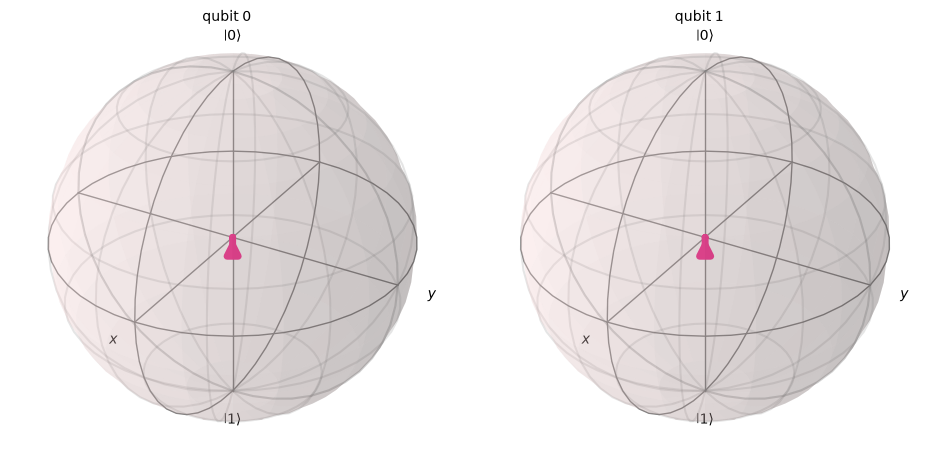

In [4]:
plot_bloch_multivector(psi_f)

In [5]:
import qiskit.quantum_info as qi
# Create the density matrix from the state vector
rho_f = qi.DensityMatrix(psi_f)
array_to_latex(rho_f)

<IPython.core.display.Latex object>

In [6]:
# Check if the density matrix is valid 
# (i.e., it is Hermitian, positive semi-definite, and has trace 1)
rho_f.is_valid()

True

In [7]:
# Trace out qubit 1 to get the reduced density matrix for qubit 0
rho_f_q0 = qi.partial_trace(rho_f, [1])  # Trace out qubit 1
array_to_latex(rho_f_q0)

<IPython.core.display.Latex object>

In [8]:
# Calculate the purity of the reduced density matrix for qubit 0, 
# i.e., Tr(rho^2). For a pure state, the purity is 1, while for a mixed state, 
# it is less than 1.
rho_f.purity()

np.complex128(1+0j)

In [9]:
# Calculate the purity of the reduced density matrix for qubit 0
rho_f_q0.purity()

np.complex128(0.5+0j)

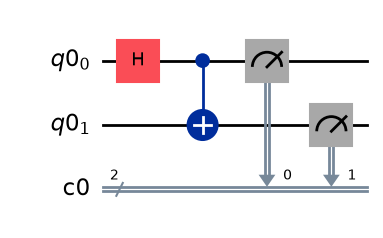

In [10]:
cr = ClassicalRegister(2)
qc = QuantumCircuit(qr, cr)
qc.h(qr[0])
qc.cx(qr[0], qr[1])
qc.measure(qr, cr)
qc.draw('mpl')

In [11]:
# qasm is a quantum assembly language that describes quantum circuits. 
# The qasm_simulator backend simulates the execution of quantum circuits and 
# returns measurement results, allowing you to analyze the behavior of quantum 
# algorithms on classical computers.

# The difference between the statevector_simulator and the qasm_simulator is that the
# statevector_simulator provides the full quantum state (amplitudes) of the system,
# while the qasm_simulator provides only the measurement outcomes (classical bits)

backend = Aer.get_backend('qasm_simulator')
job = backend.run(qc, shots=1024)
counts = job.result().get_counts(qc)
print(counts)

{'11': 496, '00': 528}


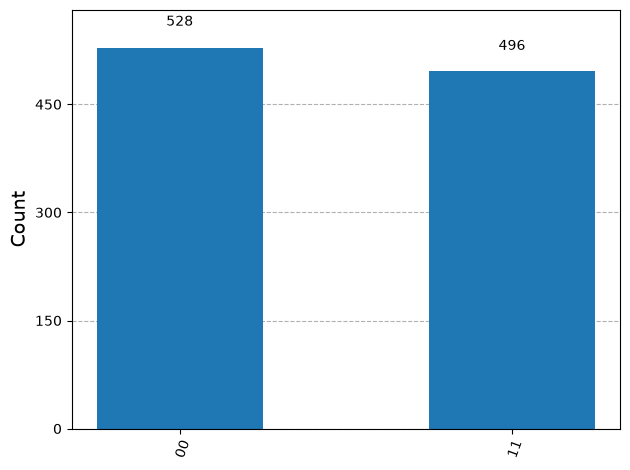

In [12]:
from qiskit.visualization import plot_histogram
plot_histogram(counts)

In [13]:
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

## Backends and `FakeManilaV2`

A **backend** is the system that executes a quantum circuit: a **simulator** or a **real quantum processor**. It also provides information such as the number of qubits, the available gates and their connectivity.

```python
from qiskit_ibm_runtime.fake_provider import FakeManilaV2
```

`FakeManilaV2` is a **simulated 5-qubit backend** that imitates IBM's Manila processor using stored data (a *snapshot*). With Qiskit Aer installed, it runs **locally** with an approximate noise model. No real quantum hardware is used.

Before running a circuit, `transpile` adapts it to the backend's **native gates** and **qubit connectivity**.

### Expected results for the Bell circuit

$$
|\Phi^+\rangle=\frac{|00\rangle+|11\rangle}{\sqrt2}
$$

- **Ideal simulator:** only `00` and `11`, each with probability $1/2$.
- **Noisy backend:** mostly `00` and `11`, but typically also some `01` and `10`.

The unwanted results come from **gate errors**, **decoherence** and **readout errors**. With quantum noise, the state is generally **mixed** and is described by a density matrix $\rho$.

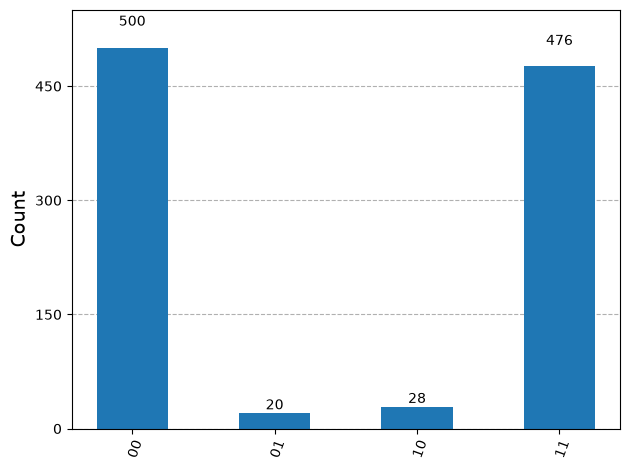

In [14]:
backend = FakeManilaV2()
counts = backend.run(qc, shots=1024).result().get_counts(qc)
plot_histogram(counts)

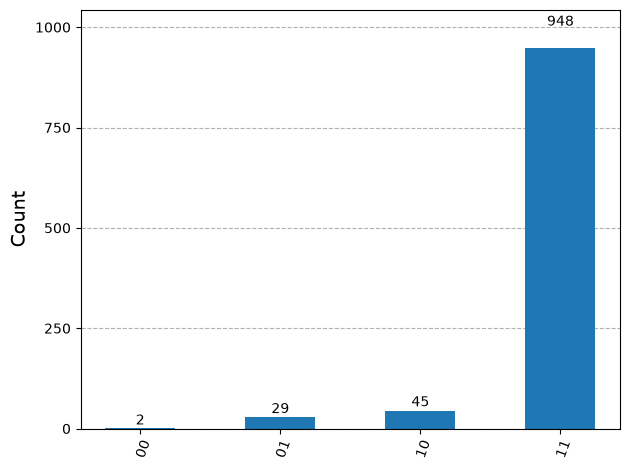

In [15]:
qc = QuantumCircuit(qr, cr)
qc.x(qr)
qc.measure(qr, cr)
counts = backend.run(qc, shots=1024).result().get_counts(qc)
plot_histogram(counts)

In [16]:
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit.circuit.library import Initialize

In [17]:
psi = qi.Statevector.from_label('1')
array_to_latex(psi)

<IPython.core.display.Latex object>

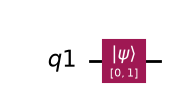

In [18]:
qr = QuantumRegister(1)
qc = QuantumCircuit(qr)
init_gate = Initialize(psi)
qc.append(init_gate, qr)
qc.draw('mpl')

In [19]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import Aer

In [20]:
backend = Aer.get_backend('qasm_simulator')
target = backend.target
pm = generate_preset_pass_manager(basis_gates=['id', 'rz', 'rx', 'cz', 'x', 'sx'])

In [21]:
qc_t = pm.run(qc)
qc_t.draw()

┌────────┐┌────────┐
q1: ─|0>─┤ Rx(-π) ├┤ Rz(-π) ├
         └────────┘└────────┘

In [22]:
# Here sth is missing

In [23]:
qc_t = pm.run(qc)
qc_t.draw()

┌────────┐┌────────┐
q1: ─|0>─┤ Rx(-π) ├┤ Rz(-π) ├
         └────────┘└────────┘

In [24]:
# Here sth is missing

In [25]:
backend = Aer.get_backend('statevector_simulator')
psi_f = backend.run(qc).result().get_statevector(qc)
array_to_latex(psi_f)

<IPython.core.display.Latex object>

In [26]:
from qiskit import quantum_info as qi
from qiskit.visualization import array_to_latex

In [27]:
I = qi.SparsePauliOp('I')
X = qi.SparsePauliOp('X')
Y = qi.SparsePauliOp('Y')
Z = qi.SparsePauliOp('Z')

O = 0.5 * (X ^ I) - 0.1 * (I ^ Z)
array_to_latex(O)

<IPython.core.display.Latex object>

In [28]:
O.is_unitary()

False

**AFTERNOON**

In [29]:
D = qi.SparsePauliOp.from_list([("XII", 1.5),("IYI",1.0)])
array_to_latex(D)


<IPython.core.display.Latex object>

In [30]:
O1 = (X ^ I) ^ I
O2 = X ^ (I ^ I)

In [31]:
O1 == O2

True

In [32]:
O = qi.SparsePauliOp.from_sparse_list(
    [("X", [2], 1.5), ("Y", [1], 1.0)],
    num_qubits=3
)
array_to_latex(O)

<IPython.core.display.Latex object>

In [33]:
# Lie-Trotter aproximation: e^(A+B) ~= e^A * e^B
# Suzuki-Trotter aproximation: e^(A+B) ~= e^(B/2) * e^(A) * e^(B/2)

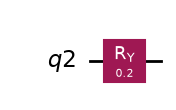

In [34]:
from qiskit import QuantumRegister, QuantumCircuit, ClassicalRegister
qr = QuantumRegister(1)
qc = QuantumCircuit(qr)

t = 0.1
qc.ry(2*t, qr)
qc.draw('mpl')

In [35]:
from qiskit_aer import Aer
backend = Aer.get_backend('statevector_simulator')
psi_f = backend.run(qc).result().get_statevector()
array_to_latex(psi_f)

<IPython.core.display.Latex object>

In [36]:
from qiskit import QuantumCircuit
from qiskit import quantum_info as qi
from qiskit.synthesis import LieTrotter
from qiskit.circuit.library import PauliEvolutionGate

In [37]:
I = qi.SparsePauliOp('I')
X = qi.SparsePauliOp('X')
Y = qi.SparsePauliOp('Y')
Z = qi.SparsePauliOp('Z')

In [39]:
H = (Z ^ Z) - 0.1 * (X ^ I)
H == H.adjoint()

True

In [41]:
final_time = 20
num_timesteps = 10
dt = final_time / num_timesteps

In [42]:
trotter_step = PauliEvolutionGate(H, dt, synthesis=LieTrotter())

In [54]:
qc = QuantumCircuit(H.num_qubits)
for i in range(num_timesteps):
    qc.append(trotter_step, range(H.num_qubits))
    qc.barrier()
qc.draw()


┌────────────────────────┐ ░ ┌────────────────────────┐ ░ »
q_0: ┤0                       ├─░─┤0                       ├─░─»
     │  exp(-it (ZZ + XI))(2) │ ░ │  exp(-it (ZZ + XI))(2) │ ░ »
q_1: ┤1                       ├─░─┤1                       ├─░─»
     └────────────────────────┘ ░ └────────────────────────┘ ░ »
«     ┌────────────────────────┐ ░ ┌────────────────────────┐ ░ »
«q_0: ┤0                       ├─░─┤0                       ├─░─»
«     │  exp(-it (ZZ + XI))(2) │ ░ │  exp(-it (ZZ + XI))(2) │ ░ »
«q_1: ┤1                       ├─░─┤1                       ├─░─»
«     └────────────────────────┘ ░ └────────────────────────┘ ░ »
«     ┌────────────────────────┐ ░ ┌────────────────────────┐ ░ »
«q_0: ┤0                       ├─░─┤0                       ├─░─»
«     │  exp(-it (ZZ + XI))(2) │ ░ │  exp(-it (ZZ + XI))(2) │ ░ »
«q_1: ┤1                       ├─░─┤1                       ├─░─»
«     └────────────────────────┘ ░ └────────────────────────┘ ░ »
«     ┌────────────────────────┐ ░ ┌────────────────────────┐ ░ »
«q_0: ┤0                       ├─░─┤0                       ├─░─»
«     │  exp(-it (ZZ + XI))(2) │ ░ │  exp(-it (ZZ + XI))(2) │ ░ »
«q_1: ┤1                       ├─░─┤1                       ├─░─»
«     └────────────────────────┘ ░ └────────────────────────┘ ░ »
«     ┌────────────────────────┐ ░ ┌────────────────────────┐ ░ 
«q_0: ┤0                       ├─░─┤0                       ├─░─
«     │  exp(-it (ZZ + XI))(2) │ ░ │  exp(-it (ZZ + XI))(2) │ ░ 
«q_1: ┤1                       ├─░─┤1                       ├─░─
«     └────────────────────────┘ ░ └────────────────────────┘ ░

In [55]:
qc.d = qc.decompose(reps=2)
qc.d.draw()

░                                  ░ »
q_0: ──■─────────────■────────────────░───■─────────────■────────────────░─»
     ┌─┴─┐┌───────┐┌─┴─┐┌───────────┐ ░ ┌─┴─┐┌───────┐┌─┴─┐┌───────────┐ ░ »
q_1: ┤ X ├┤ Rz(4) ├┤ X ├┤ R(-0.4,0) ├─░─┤ X ├┤ Rz(4) ├┤ X ├┤ R(-0.4,0) ├─░─»
     └───┘└───────┘└───┘└───────────┘ ░ └───┘└───────┘└───┘└───────────┘ ░ »
«                                      ░                                  ░ »
«q_0: ──■─────────────■────────────────░───■─────────────■────────────────░─»
«     ┌─┴─┐┌───────┐┌─┴─┐┌───────────┐ ░ ┌─┴─┐┌───────┐┌─┴─┐┌───────────┐ ░ »
«q_1: ┤ X ├┤ Rz(4) ├┤ X ├┤ R(-0.4,0) ├─░─┤ X ├┤ Rz(4) ├┤ X ├┤ R(-0.4,0) ├─░─»
«     └───┘└───────┘└───┘└───────────┘ ░ └───┘└───────┘└───┘└───────────┘ ░ »
«                                      ░                                  ░ »
«q_0: ──■─────────────■────────────────░───■─────────────■────────────────░─»
«     ┌─┴─┐┌───────┐┌─┴─┐┌───────────┐ ░ ┌─┴─┐┌───────┐┌─┴─┐┌───────────┐ ░ »
«q_1: ┤ X ├┤ Rz(4) ├┤ X ├┤ R(-0.4,0) ├─░─┤ X ├┤ Rz(4) ├┤ X ├┤ R(-0.4,0) ├─░─»
«     └───┘└───────┘└───┘└───────────┘ ░ └───┘└───────┘└───┘└───────────┘ ░ »
«                                      ░                                  ░ »
«q_0: ──■─────────────■────────────────░───■─────────────■────────────────░─»
«     ┌─┴─┐┌───────┐┌─┴─┐┌───────────┐ ░ ┌─┴─┐┌───────┐┌─┴─┐┌───────────┐ ░ »
«q_1: ┤ X ├┤ Rz(4) ├┤ X ├┤ R(-0.4,0) ├─░─┤ X ├┤ Rz(4) ├┤ X ├┤ R(-0.4,0) ├─░─»
«     └───┘└───────┘└───┘└───────────┘ ░ └───┘└───────┘└───┘└───────────┘ ░ »
«                                      ░                                  ░ 
«q_0: ──■─────────────■────────────────░───■─────────────■────────────────░─
«     ┌─┴─┐┌───────┐┌─┴─┐┌───────────┐ ░ ┌─┴─┐┌───────┐┌─┴─┐┌───────────┐ ░ 
«q_1: ┤ X ├┤ Rz(4) ├┤ X ├┤ R(-0.4,0) ├─░─┤ X ├┤ Rz(4) ├┤ X ├┤ R(-0.4,0) ├─░─
«     └───┘└───────┘└───┘└───────────┘ ░ └───┘└───────┘└───┘└───────────┘ ░

In [57]:
qc_d = qc.decompose(reps=2)
qc_d.depth()

40

In [58]:
len(qc_d)

50

In [62]:
import numpy as np
import scipy as sp

In [63]:
exact_times = np.linspace(0, final_time, 101)
print(exact_times)

[ 0.   0.2  0.4  0.6  0.8  1.   1.2  1.4  1.6  1.8  2.   2.2  2.4  2.6
  2.8  3.   3.2  3.4  3.6  3.8  4.   4.2  4.4  4.6  4.8  5.   5.2  5.4
  5.6  5.8  6.   6.2  6.4  6.6  6.8  7.   7.2  7.4  7.6  7.8  8.   8.2
  8.4  8.6  8.8  9.   9.2  9.4  9.6  9.8 10.  10.2 10.4 10.6 10.8 11.
 11.2 11.4 11.6 11.8 12.  12.2 12.4 12.6 12.8 13.  13.2 13.4 13.6 13.8
 14.  14.2 14.4 14.6 14.8 15.  15.2 15.4 15.6 15.8 16.  16.2 16.4 16.6
 16.8 17.  17.2 17.4 17.6 17.8 18.  18.2 18.4 18.6 18.8 19.  19.2 19.4
 19.6 19.8 20. ]


In [ ]:
# Missing things.....
%backend = Aer.get_backend('statevector_simulator')
%final_state = backend.run(qc).result().get_statevector()
%array_to_latex(final_state, precision = 6)

UsageError: Line magic function `%backend` not found.


In [66]:
intial_state = qi.Statevector.from_int(0, dims = 2**H.num_qubits)
array_to_latex(intial_state)

<IPython.core.display.Latex object>